# Detección de Fraude Financiero con Machine Learning
## Notebook 01 · Comprensión del negocio y de los datos
**Proyecto Final – Minería de Datos · Metodología CRISP-DM (fases 1 y 2)**

| Fase CRISP-DM | Contenido de este notebook |
|---|---|
| 1. Comprensión del negocio | Problema, impacto económico, objetivos de negocio y de minería, criterios de éxito |
| 2. Comprensión de los datos | Calidad de datos, desbalance, `Amount`, `Time`, correlaciones, separabilidad y valores atípicos |

Las figuras se guardan en `reports/figures/` para el documento técnico IEEE.

---
# Fase 1 · Comprensión del negocio

### 1.1 Problema
El uso no autorizado de tarjetas de crédito genera pérdidas a bancos, comercios y titulares. Según *The Nilson Report*, las pérdidas globales por fraude con tarjetas de pago superaron los 33 000 millones de dólares en 2023 *(verificar la cifra y la edición exacta antes de citarla en el artículo)*. La entidad financiera necesita identificar las transacciones fraudulentas en tiempo casi real, para bloquearlas antes de que se complete el pago, sin afectar a los clientes legítimos.

### 1.2 Objetivo de negocio
Reducir la pérdida económica por fraude manteniendo un volumen de alertas que el equipo de revisión pueda atender.

### 1.3 Objetivo de minería de datos
Construir un modelo de clasificación binaria que estime, para cada transacción, la probabilidad de que sea fraude (`Class = 1`). Se complementa con un modelo no supervisado de detección de anomalías (autoencoder) que no depende de las etiquetas.

### 1.4 Costo de los errores

| Error | Significado | Consecuencia para el negocio |
|---|---|---|
| Falso negativo (FN) | Fraude no detectado | Se pierde el monto de la transacción, más el costo del contracargo |
| Falso positivo (FP) | Transacción legítima bloqueada | Costo de revisión manual y molestia al cliente (riesgo de abandono) |

Un falso negativo cuesta bastante más que un falso positivo. Por eso se prioriza el **Recall** sin descuidar la **Precision**: un sistema que bloquea demasiadas transacciones legítimas tampoco es viable.

### 1.5 Criterios de éxito (medidos en el conjunto de prueba)

| Criterio | Meta | Justificación |
|---|---|---|
| Recall (fraude) | ≥ 0,80 | Detectar al menos 8 de cada 10 fraudes |
| Precision (fraude) | ≥ 0,70 | Menos de 1 falsa alarma por cada 2 fraudes detectados |
| PR-AUC (Average Precision) | ≥ 0,80 | Métrica global adecuada para clases muy desbalanceadas |
| Costo total | Menor que no usar modelo | El sistema debe ahorrar dinero |

El *accuracy* **no** se usa como criterio: con tan pocos fraudes, un modelo que nunca detecta fraude tendría un *accuracy* cercano al 100 %.

### 1.6 Recursos, supuestos y riesgos
- **Datos:** 284 807 transacciones de tarjetas europeas (septiembre de 2013, 2 días). Sin identificador de cliente ni de comercio.
- **Anonimización:** 28 variables son componentes PCA (`V1`–`V28`); no se conoce su significado de negocio. Esto limita la interpretación de los resultados.
- **Antigüedad:** los patrones de fraude de 2013 pueden diferir de los actuales (*concept drift*). En producción el modelo debe reentrenarse periódicamente.
- **Herramientas:** Python 3.11, scikit-learn, imbalanced-learn, XGBoost, TensorFlow/Keras, SHAP y Streamlit.

---
# Configuración del entorno

In [1]:
import sys
from pathlib import Path

# Permite importar src/ tanto si el kernel arranca en notebooks/ como en la raíz del proyecto
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

from src.config import (
    FIG_DIR, RANDOM_STATE, COLUMNAS_V, TARGET,
    COLOR_LEGITIMA, COLOR_FRAUDE, PALETA_CLASES, NOMBRES_CLASES, fijar_semillas,
)
from src.data_preprocessing import cargar_datos, hora_del_ciclo

fijar_semillas()

# Estilo sobrio: rejilla tenue y sin bordes superior/derecho, para que destaquen los datos
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.35,
    "grid.linewidth": 0.6,
})
COLOR_TEXTO = "#52514e"   # gris para líneas de referencia

def guardar_figura(nombre):
    """Guarda la figura actual en reports/figures para el artículo IEEE."""
    plt.savefig(FIG_DIR / nombre, bbox_inches="tight", dpi=150)

print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: C:\Users\JAMN\fraud-detection


---
# Fase 2 · Comprensión de los datos

### 2.1 Descripción de las variables

| Variable | Tipo | Descripción |
|---|---|---|
| `Time` | numérica | Segundos transcurridos desde la primera transacción del dataset |
| `V1`–`V28` | numéricas | Componentes principales (PCA) de variables originales confidenciales |
| `Amount` | numérica | Monto de la transacción (euros) |
| `Class` | binaria | 1 = fraude, 0 = legítima (variable objetivo) |

In [2]:
df = cargar_datos()
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.head()

Filas: 284,807 | Columnas: 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### 2.2 Calidad de los datos
Se revisan tipos de dato, valores nulos y registros duplicados.

In [3]:
df.info(memory_usage="deep")

print("\nValores nulos totales:", int(df.isnull().sum().sum()))
print("Tipos de dato:", {str(tipo): int(n) for tipo, n in df.dtypes.value_counts().items()})

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [4]:
# Duplicados exactos: mismas 31 variables y misma etiqueta
duplicados = df.duplicated(keep="first")
print(f"Filas duplicadas exactas (copias sobrantes): {duplicados.sum():,} "
      f"({duplicados.mean():.2%} del total)")
print("Copias sobrantes por clase:",
      df.loc[duplicados, TARGET].value_counts().rename(NOMBRES_CLASES).to_dict())

# ¿Hay transacciones idénticas con etiquetas distintas? (serían datos contradictorios)
columnas_x = df.columns.drop(TARGET).tolist()
grupos_repetidos = df[df.duplicated(subset=columnas_x, keep=False)].groupby(columnas_x)[TARGET].nunique()
print("Grupos idénticos con etiqueta contradictoria:", int((grupos_repetidos > 1).sum()))

print(f"\nFraudes únicos tras eliminar duplicados: {int(df.drop_duplicates()[TARGET].sum())}")

Filas duplicadas exactas (copias sobrantes): 1,081 (0.38% del total)
Copias sobrantes por clase: {'Legítima': 1062, 'Fraude': 19}


Grupos idénticos con etiqueta contradictoria: 0



Fraudes únicos tras eliminar duplicados: 473


### 2.3 Distribución de la variable objetivo

,Transacciones,Porcentaje (%)
Class,,
Legítima,284315,99.827
Fraude,492,0.173


Razón de desbalance: 1 fraude por cada 578 transacciones legítimas
Accuracy de un modelo que siempre responde 'legítima': 99.8273%


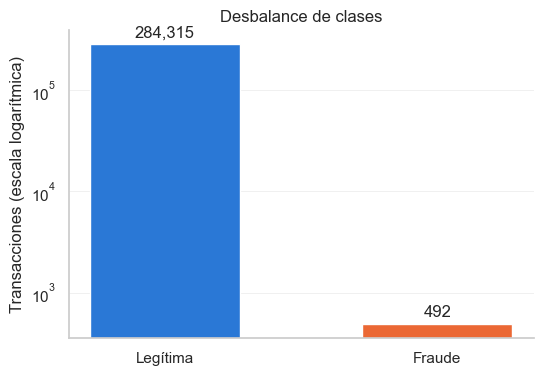

In [5]:
conteo = df[TARGET].value_counts().sort_index()
resumen_clases = pd.DataFrame({
    "Transacciones": conteo,
    "Porcentaje (%)": (conteo / conteo.sum() * 100).round(3),
}).rename(index=NOMBRES_CLASES)
display(resumen_clases)

print(f"Razón de desbalance: 1 fraude por cada {conteo[0] / conteo[1]:.0f} transacciones legítimas")
print(f"Accuracy de un modelo que siempre responde 'legítima': {conteo[0] / conteo.sum():.4%}")

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar([NOMBRES_CLASES[0], NOMBRES_CLASES[1]], conteo.values,
                color=[COLOR_LEGITIMA, COLOR_FRAUDE], width=0.55)
ax.set_yscale("log")
ax.set_ylabel("Transacciones (escala logarítmica)")
ax.set_title("Desbalance de clases")
ax.bar_label(barras, labels=[f"{v:,}" for v in conteo.values], padding=3)
ax.grid(axis="x", visible=False)
guardar_figura("01_desbalance_clases.png")
plt.show()

### 2.4 Monto de la transacción (`Amount`)

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
Legítima,284315.0,88.29,250.11,0.0,5.65,22.00,77.05,25691.16
Fraude,492.0,122.21,256.68,0.0,1.00,9.25,105.89,2125.87


Transacciones con monto 0: {'Legítima': 1798, 'Fraude': 27}
Asimetría de Amount: 16.98 | tras log(1 + x): 0.16
Mann-Whitney U (montos fraude vs. legítima): p-valor = 8.58e-06


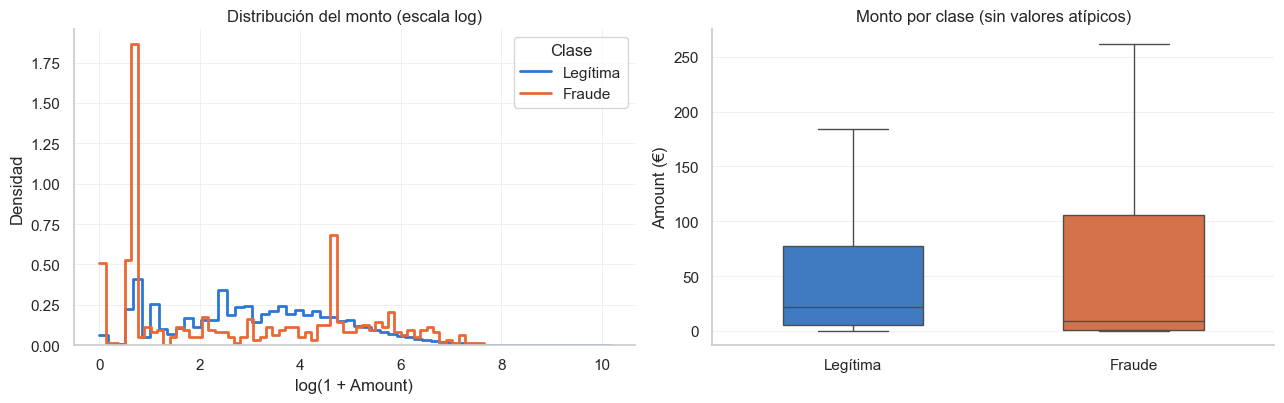

In [6]:
display(df.groupby(TARGET)["Amount"].describe().rename(index=NOMBRES_CLASES).round(2))

print("Transacciones con monto 0:",
      df[df["Amount"] == 0].groupby(TARGET).size().rename(NOMBRES_CLASES).to_dict())
print(f"Asimetría de Amount: {df['Amount'].skew():.2f} | tras log(1 + x): {np.log1p(df['Amount']).skew():.2f}")

# Prueba no paramétrica: ¿los montos de fraude y legítimas vienen de la misma distribución?
u = stats.mannwhitneyu(df.loc[df[TARGET] == 1, "Amount"], df.loc[df[TARGET] == 0, "Amount"])
print(f"Mann-Whitney U (montos fraude vs. legítima): p-valor = {u.pvalue:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for clase in (0, 1):
    sns.histplot(np.log1p(df.loc[df[TARGET] == clase, "Amount"]), stat="density", bins=60,
                 element="step", fill=False, linewidth=2, color=PALETA_CLASES[clase],
                 label=NOMBRES_CLASES[clase], ax=axes[0])
axes[0].set(xlabel="log(1 + Amount)", ylabel="Densidad", title="Distribución del monto (escala log)")
axes[0].legend(title="Clase")

sns.boxplot(data=df, x=TARGET, y="Amount", hue=TARGET, palette=PALETA_CLASES,
            showfliers=False, legend=False, width=0.5, ax=axes[1])
axes[1].set_xticks([0, 1], [NOMBRES_CLASES[0], NOMBRES_CLASES[1]])
axes[1].set(xlabel="", ylabel="Amount (€)", title="Monto por clase (sin valores atípicos)")
plt.tight_layout()
guardar_figura("02_monto_por_clase.png")
plt.show()

### 2.5 Dimensión temporal (`Time`)
`Time` cubre unas 48 horas. Se analiza la distribución por clase y, asumiendo que el registro empieza a medianoche, el volumen y la tasa de fraude por hora del día.

Rango de Time: 0 s a 172,792 s (48.0 horas)


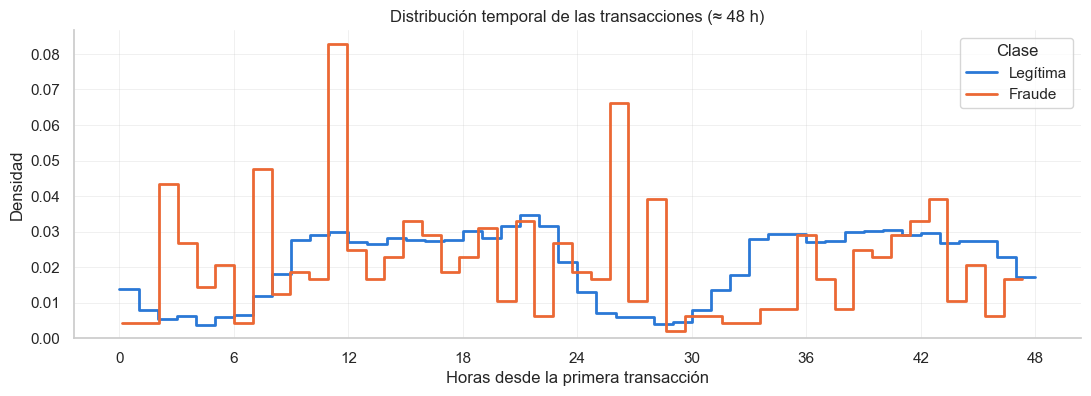

In [7]:
horas = df["Time"] / 3600
print(f"Rango de Time: {df['Time'].min():.0f} s a {df['Time'].max():,.0f} s ({horas.max():.1f} horas)")

fig, ax = plt.subplots(figsize=(13, 4))
for clase in (0, 1):
    sns.histplot(horas[df[TARGET] == clase], stat="density", bins=48, element="step",
                 fill=False, linewidth=2, color=PALETA_CLASES[clase],
                 label=NOMBRES_CLASES[clase], ax=ax)
ax.set(xlabel="Horas desde la primera transacción", ylabel="Densidad",
       title="Distribución temporal de las transacciones (≈ 48 h)")
ax.set_xticks(range(0, 49, 6))
ax.legend(title="Clase")
guardar_figura("03_time_por_clase.png")
plt.show()

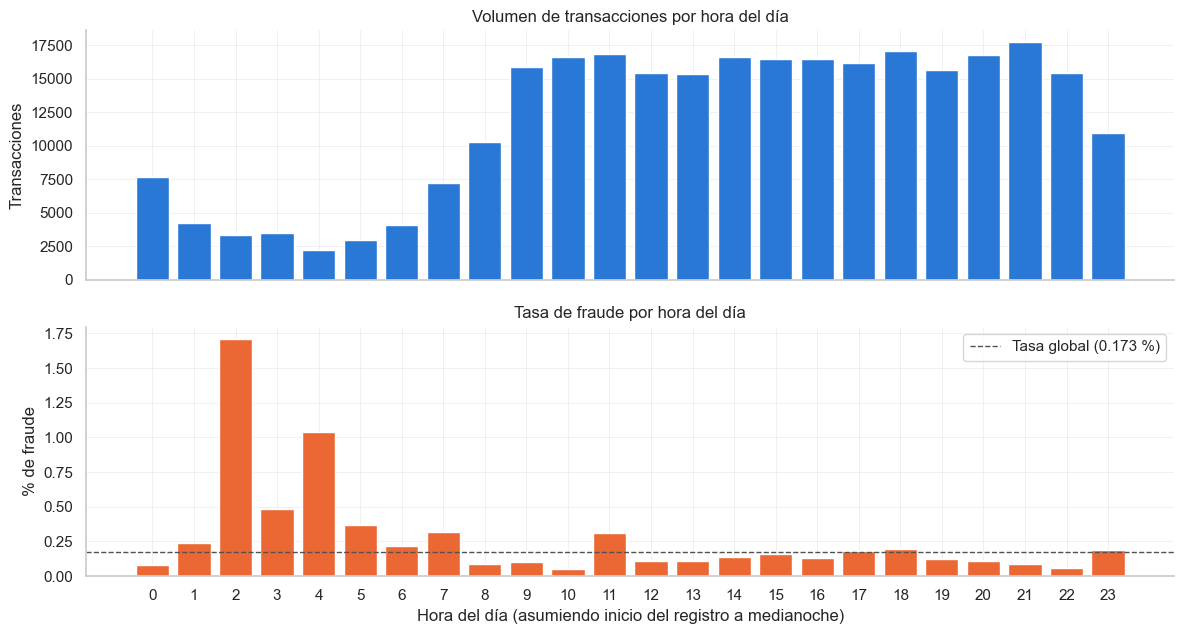

Horas con mayor tasa de fraude:


,Transacciones,Fraudes,Tasa de fraude (%)
Hora,,,
2,3328,57,1.713
4,2209,23,1.041
3,3492,17,0.487
5,2990,11,0.368
7,7243,23,0.318


In [8]:
por_hora = (df.assign(Hora=hora_del_ciclo(df["Time"]).astype(int))
              .groupby("Hora")
              .agg(Transacciones=(TARGET, "size"), Fraudes=(TARGET, "sum")))
por_hora["Tasa de fraude (%)"] = por_hora["Fraudes"] / por_hora["Transacciones"] * 100
tasa_global = df[TARGET].mean() * 100

# Dos paneles con eje propio (no se usa doble eje Y, que confunde la lectura)
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
axes[0].bar(por_hora.index, por_hora["Transacciones"], color=COLOR_LEGITIMA, width=0.8)
axes[0].set(ylabel="Transacciones", title="Volumen de transacciones por hora del día")
axes[1].bar(por_hora.index, por_hora["Tasa de fraude (%)"], color=COLOR_FRAUDE, width=0.8)
axes[1].axhline(tasa_global, color=COLOR_TEXTO, linestyle="--", linewidth=1,
                label=f"Tasa global ({tasa_global:.3f} %)")
axes[1].set(xlabel="Hora del día (asumiendo inicio del registro a medianoche)",
            ylabel="% de fraude", title="Tasa de fraude por hora del día")
axes[1].set_xticks(range(24))
axes[1].legend()
plt.tight_layout()
guardar_figura("04_patron_horario.png")
plt.show()

print("Horas con mayor tasa de fraude:")
display(por_hora.sort_values("Tasa de fraude (%)", ascending=False).head(5).round(3))

### 2.6 Correlaciones

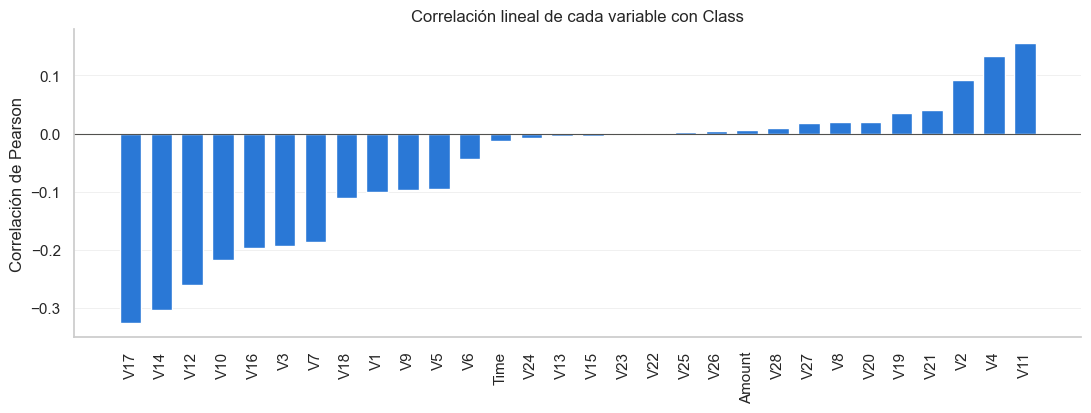

Variables con mayor |correlación| con el fraude:
V17    0.326
V14    0.303
V12    0.261
V10    0.217
V16    0.197
V3     0.193
V7     0.187
V11    0.155
V4     0.133
V18    0.111


In [9]:
correlaciones = df.drop(columns=TARGET).corrwith(df[TARGET]).sort_values()

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(correlaciones.index, correlaciones.values, color=COLOR_LEGITIMA, width=0.7)
ax.axhline(0, color=COLOR_TEXTO, linewidth=0.8)
ax.set(ylabel="Correlación de Pearson", title="Correlación lineal de cada variable con Class")
ax.tick_params(axis="x", rotation=90)
ax.grid(axis="x", visible=False)
guardar_figura("05_correlacion_con_clase.png")
plt.show()

print("Variables con mayor |correlación| con el fraude:")
print(correlaciones.abs().sort_values(ascending=False).head(10).round(3).to_string())

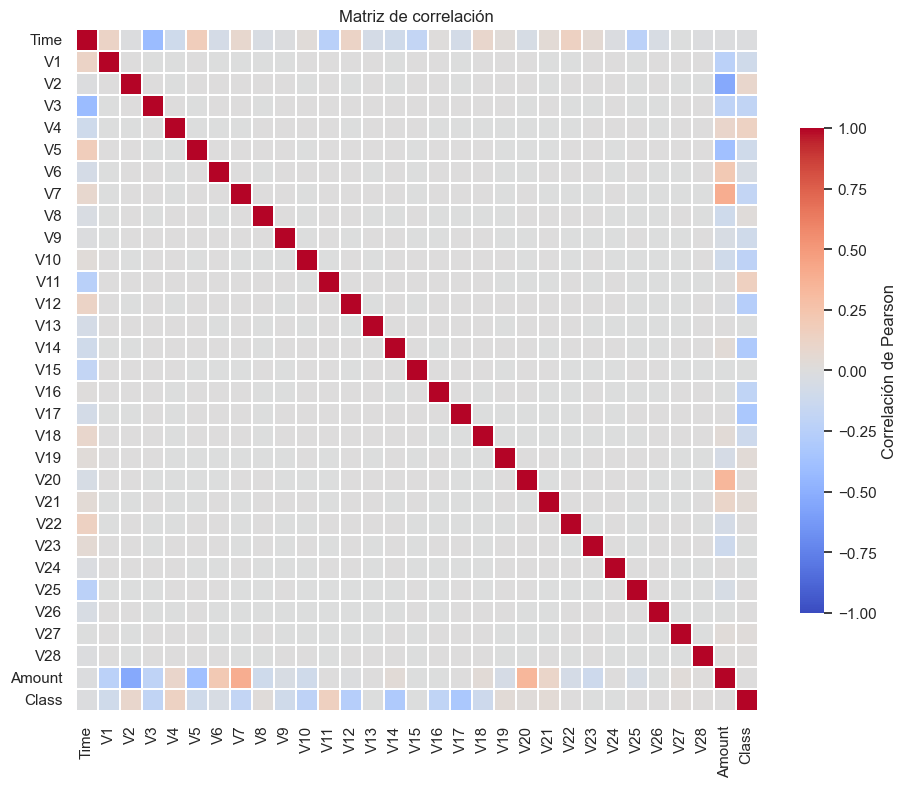

Máxima |correlación| entre pares Vi–Vj: 0.0000
Variables V más correlacionadas con Amount: {'V2': 0.531, 'V7': 0.397, 'V5': 0.386, 'V20': 0.339}
Variables V más correlacionadas con Time: {'V3': 0.42, 'V11': 0.248, 'V25': 0.233, 'V15': 0.183}


In [10]:
matriz = df.corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(matriz, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, linewidths=0.3,
            cbar_kws={"shrink": 0.7, "label": "Correlación de Pearson"}, ax=ax)
ax.set_title("Matriz de correlación")
guardar_figura("06_matriz_correlacion.png")
plt.show()

v = matriz.loc[COLUMNAS_V, COLUMNAS_V].values
print(f"Máxima |correlación| entre pares Vi–Vj: {np.abs(v[np.triu_indices_from(v, k=1)]).max():.4f}")
print("Variables V más correlacionadas con Amount:",
      matriz.loc[COLUMNAS_V, "Amount"].abs().sort_values(ascending=False).head(4).round(3).to_dict())
print("Variables V más correlacionadas con Time:",
      matriz.loc[COLUMNAS_V, "Time"].abs().sort_values(ascending=False).head(4).round(3).to_dict())

### 2.7 Separabilidad de las clases
La correlación de Pearson solo mide relaciones lineales. El estadístico de **Kolmogórov-Smirnov (KS)** compara la distribución completa de cada variable en fraudes y en legítimas: 0 = distribuciones iguales, 1 = totalmente separadas.

Variable,V14,V10,V12,V4,V11,V17,V3,V16,V7,V2
KS,0.843,0.804,0.784,0.766,0.756,0.745,0.704,0.687,0.661,0.633


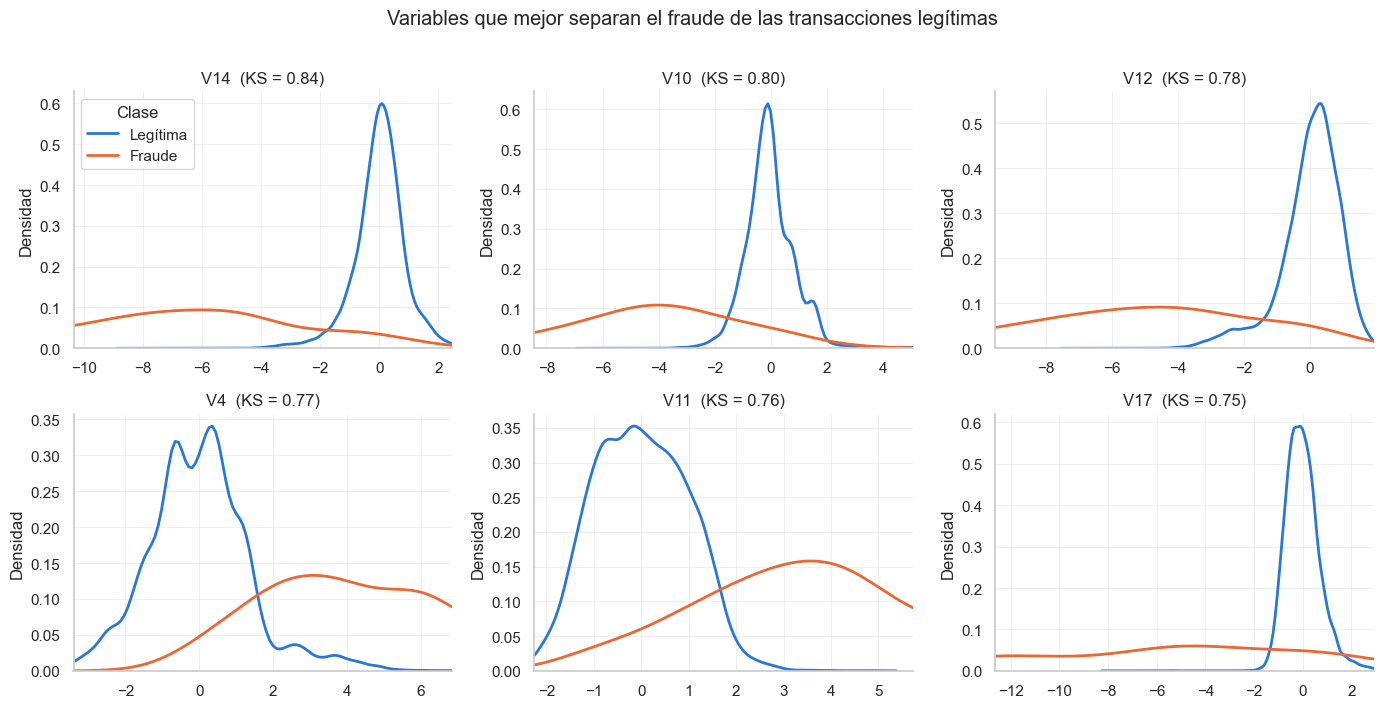

In [11]:
fraudes = df[df[TARGET] == 1]
legitimas = df[df[TARGET] == 0]

ks = (pd.DataFrame([
        {"Variable": c, "KS": stats.ks_2samp(fraudes[c], legitimas[c]).statistic}
        for c in COLUMNAS_V + ["Amount", "Time"]
      ])
      .set_index("Variable")
      .sort_values("KS", ascending=False))
display(ks.head(10).round(3).T)

# Para las curvas de densidad basta una muestra de legítimas (todas las fraudes se conservan)
muestra = pd.concat([legitimas.sample(20_000, random_state=RANDOM_STATE), fraudes])
top6 = ks.index[:6].tolist()

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, var in zip(axes.ravel(), top6):
    for clase in (0, 1):
        sns.kdeplot(muestra.loc[muestra[TARGET] == clase, var], ax=ax, linewidth=2,
                    color=PALETA_CLASES[clase], label=NOMBRES_CLASES[clase])
    ax.set_xlim(*muestra[var].quantile([0.005, 0.995]))
    ax.set(title=f"{var}  (KS = {ks.loc[var, 'KS']:.2f})", xlabel="", ylabel="Densidad")
axes[0, 0].legend(title="Clase")
fig.suptitle("Variables que mejor separan el fraude de las transacciones legítimas", y=1.01)
plt.tight_layout()
guardar_figura("07_variables_mas_separables.png")
plt.show()

### 2.8 Valores atípicos (outliers)
Se marca como atípico un valor fuera de $[Q_1 - 1{,}5\,IQR,\; Q_3 + 1{,}5\,IQR]$, con los cuartiles calculados sobre todo el dataset. Luego se compara qué proporción de atípicos hay en cada clase.

,% atípicos (total),% en legítimas,% en fraudes
Variable,,,
V14,4.97,4.83,87.40
V12,5.39,5.25,83.13
V10,3.33,3.20,81.10
V17,2.61,2.47,80.69
V16,2.87,2.76,71.34
V27,13.75,13.65,69.92
V4,3.91,3.81,64.63
V3,1.18,1.07,63.41
V7,3.14,3.04,61.18


Transacciones con al menos una variable atípica:
  Legítimas: 48.54%
  Fraudes:   96.95%


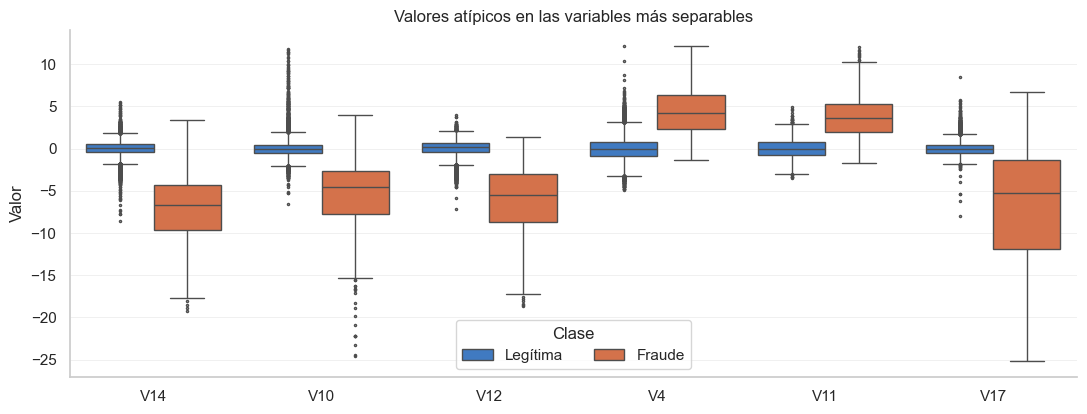

In [12]:
filas = []
algun_atipico = pd.Series(False, index=df.index)
for c in COLUMNAS_V + ["Amount"]:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    fuera = (df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)
    algun_atipico |= fuera
    filas.append({
        "Variable": c,
        "% atípicos (total)": fuera.mean() * 100,
        "% en legítimas": fuera[df[TARGET] == 0].mean() * 100,
        "% en fraudes": fuera[df[TARGET] == 1].mean() * 100,
    })
atipicos = pd.DataFrame(filas).set_index("Variable").sort_values("% en fraudes", ascending=False)
display(atipicos.head(10).round(2))

print("Transacciones con al menos una variable atípica:")
print(f"  Legítimas: {algun_atipico[df[TARGET] == 0].mean():.2%}")
print(f"  Fraudes:   {algun_atipico[df[TARGET] == 1].mean():.2%}")

largo = muestra.melt(id_vars=TARGET, value_vars=top6, var_name="Variable", value_name="Valor")
fig, ax = plt.subplots(figsize=(13, 4.5))
sns.boxplot(data=largo, x="Variable", y="Valor", hue=TARGET, palette=PALETA_CLASES,
            fliersize=1.5, linewidth=1, ax=ax)
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, [NOMBRES_CLASES[0], NOMBRES_CLASES[1]], title="Clase", loc="lower center", ncol=2)
ax.set(xlabel="", title="Valores atípicos en las variables más separables")
guardar_figura("08_outliers_por_clase.png")
plt.show()

---
# Resumen de hallazgos y decisiones para la Fase 3

### Hallazgos principales

1. **Calidad de datos.** No hay valores nulos y las 31 columnas son numéricas. Hay **1 081 filas duplicadas** exactas (0,38 %), 19 de ellas fraudes, y ninguna transacción idéntica con etiquetas contradictorias. Tras eliminarlas quedan **473 fraudes únicos**.
2. **Desbalance extremo.** 492 fraudes de 284 807 transacciones (**0,173 %**, 1 fraude por cada 578 legítimas). Un modelo que siempre responde "legítima" obtiene un *accuracy* de 99,83 % sin detectar ningún fraude.
3. **Monto (`Amount`).** Distribución muy asimétrica (asimetría 16,98; tras `log(1 + x)` baja a 0,16). La mediana del fraude (9,25 €) es menor que la de las legítimas (22,00 €), pero su media es mayor (122,21 € frente a 88,29 €). El 25 % de los fraudes es de **1,00 € o menos**, un patrón compatible con *card testing* (pruebas de la tarjeta robada con montos pequeños). La diferencia es significativa (Mann-Whitney, p = 8,6 × 10⁻⁶). Hay 1 825 transacciones con monto 0, 27 de ellas fraudes.
4. **Tiempo (`Time`).** Cubre 48 horas con un ciclo diario claro: el volumen cae de madrugada. En esas horas la **tasa de fraude se dispara**: 1,71 % a las 2 h (unas 10 veces la tasa global) y 1,04 % a las 4 h.
5. **Correlaciones.** Las variables `V1`–`V28` no están correlacionadas entre sí (máxima |r| ≈ 0, por construcción del PCA), así que no hay multicolinealidad. `Amount` se relaciona con `V2` (0,53), `V7` y `V5`, y `Time` con `V3` (0,42). Con `Class` las correlaciones lineales son débiles; las mayores son `V17` (0,33), `V14` (0,30), `V12` (0,26) y `V10` (0,22).
6. **Separabilidad.** El estadístico KS muestra que varias variables separan muy bien las clases, aunque la relación no sea lineal: `V14` (0,84), `V10` (0,80), `V12` (0,78), `V4` (0,77), `V11` (0,76) y `V17` (0,75). Se esperan buenos resultados de los modelos no lineales (árboles y redes).
7. **Valores atípicos.** El **97 % de los fraudes** tiene al menos una variable atípica, frente al 48,5 % de las legítimas. En `V14`, el 87 % de los fraudes es atípico frente al 4,8 % de las legítimas. **Los valores atípicos son la señal del fraude, no ruido.**

### Decisiones para la preparación de los datos

| Hallazgo | Decisión en la Fase 3 |
|---|---|
| 1 081 duplicados exactos | Eliminarlos **antes** de dividir, para que una misma transacción no quede en entrenamiento y en prueba |
| Desbalance 1:578 | División **estratificada**; SMOTE **solo** en entrenamiento; comparar con `class_weight` / `scale_pos_weight` |
| *Accuracy* engañoso | Evaluar con Precision, Recall, F1, ROC-AUC, **PR-AUC** y matriz de confusión |
| `Amount` muy asimétrico | Usar `Amount_log = log(1 + Amount)` y escalarlo con `RobustScaler` (mediana e IQR, resistente a atípicos) |
| Fraude concentrado de madrugada | Crear `Hour_sin` y `Hour_cos` (hora cíclica) |
| `Time` crudo es un contador de 0 a 172 792 s | No usarlo directamente: en producción tomaría valores fuera del rango visto. Su información útil (la hora del día) queda en las variables cíclicas |
| `V1`–`V28` centradas pero con varianzas distintas | Estandarizarlas (`StandardScaler`) para la red neuronal y el autoencoder; no afecta a los modelos de árboles |
| Atípicos = fraude | **No** eliminar valores atípicos. Refuerza el uso del autoencoder (detección de anomalías) |

### Limitaciones
- Las variables `V1`–`V28` son anónimas: se puede decir *qué* componente influye, pero no *qué significa* para el negocio.
- Solo hay dos días de datos. La división aleatoria estratificada que pide el enunciado no evalúa el desempeño frente a patrones futuros; en producción conviene validar con datos posteriores al entrenamiento.